In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping

import os
import random
from datetime import datetime
import time

import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9



2025-12-08 04:27:38.625929: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [6]:
import importlib
import OptimizedDataGenerator_v2

importlib.reload(OptimizedDataGenerator_v2)
from OptimizedDataGenerator_v2 import OptimizedDataGenerator
import dataset_utils

importlib.reload(dataset_utils)


<module 'dataset_utils' from '/home/bweiss/smart-pix/DAE/dataset_utils.py'>

In [3]:
#from dataprep import *
# from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *
from models import *
import time

In [4]:
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")

dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'train/')
dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'test/')

tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'3sr_16x16_Opt2bit')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'3sr_16x16_Opt2bit')

# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'3sr_16x16_80eNoise_v2')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'3sr_16x16_80eNoise_v2')

print(dataset_dir_val)
batch_size = 5000
val_batch_size = 5000
train_file_size = 80
val_file_size = 20

/uscms/home/bweiss/nobackup/smart-pixels/dataset_3sr_16x16_50x12P5_parquets/test/


In [5]:
'''CHANGE THRESHOLDS AND TO_STANDARDIZE!!'''
start_time = time.time()
validation_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_val,
    file_type = "parquet",
    data_format = "3D",
    batch_size = val_batch_size,
    # optimize_batch_size = True,
    file_count = val_file_size,
    to_standardize= False,
    log_scale = False,
    select_contained = True,
    noise = [0,80], #[mean, sigma]
    # min_threshold = 400,
    # max_threshold = 1000,
    charge_thresholds= [247.80, 668.41, 1662.85],
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, 
    files_from_end=True,

    tfrecords_dir = tfrecords_dir_val,
    use_time_stamps = [0,19],
    max_workers = 2
)
print("--- Validation generator %s seconds ---" % (time.time() - start_time))

Processing Files...:   0%|          | 0/20 [00:00<?, ?it/s]


UnboundLocalError: local variable 'data' referenced before assignment

In [4]:
# training generator
start_time = time.time()
training_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_train,
    file_type = "parquet",
    data_format = "3D",
    batch_size = batch_size,
    # optimize_batch_size = True,
    file_count = train_file_size,
    to_standardize=False,
    select_contained = True,
    log_scale = False,
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, # True 
    noise = [0,80],
    # charge_thresholds= [247.80, 668.41, 1662.85],
    charge_thresholds = None,

    # threshold = 400,
    tfrecords_dir = tfrecords_dir_train,
    use_time_stamps = [0,19],
    max_workers = 2
)

# training_generator = [training_generator[:][0], training_generator[:][0]]

print("--- Training generator %s seconds ---" % (time.time() - start_time))

NameError: name 'time' is not defined

In [9]:
# Loading pre-generated TFRecords
validation_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    seed=42,
    quantize=False,
)

training_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir = tfrecords_dir_train,
    shuffle=False,
    seed=42,
    quantize=False,
)


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3sr_16x16_Opt2bit/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3sr_16x16_Opt2bit/metadata.json


2025-12-08 04:22:10.618127: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-12-08 04:22:10.659720: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-12-08 04:22:10.660160: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-12-08 04:22:10.662014: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropri

tf.Tensor(
[[-0.90068656 -0.55719686 -0.53072673  0.1151311 ]
 [ 0.6422447   0.91322666  0.2867313  -1.046721  ]
 [ 0.86441964  0.6900523  -0.73899055 -0.51502854]
 ...
 [-0.21077555  0.4397422  -0.3037005  -0.83665574]
 [-0.23576191  0.9734979  -0.5340717  -0.0883378 ]
 [-0.17782159  0.18262872  0.5971457  -0.6473533 ]], shape=(5000, 4), dtype=float32)
max: 0.99433017
min: -0.9957506


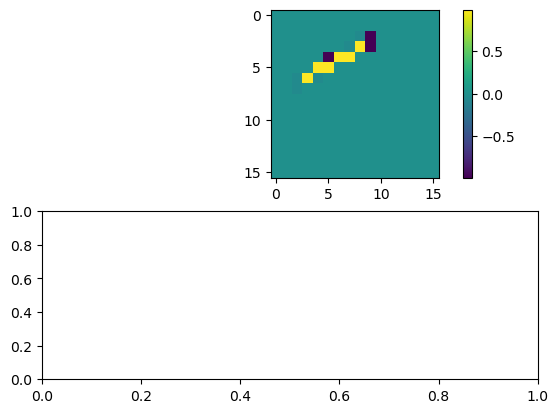

In [10]:
import matplotlib.pyplot as plt
from matplotlib import colors

n=0

cluster = validation_generator[0]
# print(np.max(cluster[0].numpy()))
print(cluster[1])
cluster=cluster[0][:,:,:,1]

print('max:', np.max(cluster.numpy()))
print('min:', np.min(cluster.numpy()))

fig,ax = plt.subplots(2,1)
h = ax[0].imshow(cluster[n])
fig.colorbar(h)

In [7]:
model=CreateModel((16,16,2),n_filters=5,pool_size=3, conv_kernel_size = 3)
model.compile(
    optimizer=tf.keras.optimizers.Nadam(learning_rate=1e-3),
    loss=custom_loss
)

model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 q_separable_conv2d (QSepara  (None, 14, 14, 5)        33        
 bleConv2D)                                                      
                                                                 
 q_activation (QActivation)  (None, 14, 14, 5)         0         
                                                                 
 q_conv2d (QConv2D)          (None, 14, 14, 5)         30        
                                                                 
 q_activation_1 (QActivation  (None, 14, 14, 5)        0         
 )                                                               
                                                                 
 average_pooling2d (AverageP  (None, 4, 4, 5)          0     

In [8]:
from datetime import datetime
tname = '3sr16x16_opt2Bit_80eNoise_v2'
fingerprint = '%08x' % random.randrange(16**8)
timestamp = datetime.now().strftime('%Y%m%d-%H%M%S')
os.makedirs("trained_models", exist_ok=True)
base_dir = f'./trained_models/model-{fingerprint}-{tname}-checkpoints'
os.makedirs(base_dir, exist_ok=True)  
checkpoint_filepath = base_dir + '/weights.{epoch:02d}-t{loss:.2f}-v{val_loss:.2f}.hdf5'

In [9]:
print(fingerprint)

d5a20f32


In [11]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, Callback

early_stopping_patience = 100

class CustomModelCheckpoint(ModelCheckpoint):
    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        checkpoints = [f for f in os.listdir(base_dir) if f.startswith('weights')]
        if len(checkpoints) > 1:
            checkpoints.sort(key=lambda x: os.path.getmtime(os.path.join(base_dir,x)))
            for checkpoint in checkpoints[:-1]:
                os.remove(os.path.join(base_dir, checkpoint))

es = EarlyStopping(patience=early_stopping_patience, restore_best_weights=True)

mcp = CustomModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    save_freq='epoch',
    verbose=1
)

csv_logger = CSVLogger(f'{base_dir}/training_log.csv', append=True)

In [12]:
history = model.fit(
        x=training_generator,
        validation_data=validation_generator,
        callbacks=[es, mcp, csv_logger],
        epochs=1000,
        shuffle=False,
        verbose=1
    )

Epoch 1/1000
 1/84 [..............................] - ETA: 3:25 - loss: 103620.0625

2025-11-18 19:43:42.215662: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2025-11-18 19:43:42.228684: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8800
2025-11-18 19:43:42.261483: I tensorflow/core/util/cuda_solvers.cc:179] Creating GpuSolver handles for stream 0x55cf31525c40


84/84 [==============================] - ETA: 0s - loss: 48934.5781
Epoch 1: val_loss improved from inf to 14974.38477, saving model to ./trained_models/model-d5a20f32-3sr16x16_opt2Bit_80eNoise_v2-checkpoints/weights.01-t48934.58-v14974.38.hdf5
84/84 [==============================] - 10s 93ms/step - loss: 48934.5781 - val_loss: 14974.3848
Epoch 2/1000
84/84 [==============================] - ETA: 0s - loss: 14282.7832
Epoch 2: val_loss improved from 14974.38477 to 13114.56934, saving model to ./trained_models/model-d5a20f32-3sr16x16_opt2Bit_80eNoise_v2-checkpoints/weights.02-t14282.78-v13114.57.hdf5
84/84 [==============================] - 7s 84ms/step - loss: 14282.7832 - val_loss: 13114.5693
Epoch 3/1000
84/84 [==============================] - ETA: 0s - loss: 11806.1104
Epoch 3: val_loss improved from 13114.56934 to 10307.85938, saving model to ./trained_models/model-d5a20f32-3sr16x16_opt2Bit_80eNoise_v2-checkpoints/weights.03-t11806.11-v10307.86.hdf5
84/84 [=======================

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



84/84 [==============================] - ETA: 0s - loss: -7453.2534
Epoch 353: val_loss did not improve from -7795.39844
84/84 [==============================] - 7s 80ms/step - loss: -7453.2534 - val_loss: -7786.0513
Epoch 354/1000
84/84 [==============================] - ETA: 0s - loss: -7429.9756
Epoch 354: val_loss did not improve from -7795.39844
84/84 [==============================] - 7s 80ms/step - loss: -7429.9756 - val_loss: -6873.8120
Epoch 355/1000
84/84 [==============================] - ETA: 0s - loss: -6942.7588
Epoch 355: val_loss did not improve from -7795.39844
84/84 [==============================] - 7s 82ms/step - loss: -6942.7588 - val_loss: -7126.0117
Epoch 356/1000
84/84 [==============================] - ETA: 0s - loss: -7413.7983
Epoch 356: val_loss did not improve from -7795.39844
84/84 [==============================] - 7s 81ms/step - loss: -7413.7983 - val_loss: -7526.8701
Epoch 357/1000
84/84 [==============================] - ETA: 0s - loss: -7494.8643
Epoc

In [ ]:
'''
Epoch 1/1000
305/305 [==============================] - ETA: 0s - loss: 27173.7227
Epoch 1: val_loss improved from inf to 3957.69629, saving model to ./trained_models/model-e0ef8b33-checkpoints/weights.01-t27173.72-v3957.70.hdf5
305/305 [==============================] - 34s 102ms/step - loss: 27173.7227 - val_loss: 3957.6963
Epoch 2/1000
305/305 [==============================] - ETA: 0s - loss: 2077.7952
Epoch 2: val_loss improved from 3957.69629 to -473.36844, saving model to ./trained_models/model-e0ef8b33-checkpoints/weights.02-t2077.80-v-473.37.hdf5
305/305 [==============================] - 30s 97ms/step - loss: 2077.7952 - val_loss: -473.3684
Epoch 3/1000
305/305 [==============================] - ETA: 0s - loss: -935.6221
Epoch 3: val_loss improved from -473.36844 to -1284.97668, saving model to ./trained_models/model-e0ef8b33-checkpoints/weights.03-t-935.62-v-1284.98.hdf5
305/305 [==============================] - 61s 199ms/step - loss: -935.6221 - val_loss: -1284.9767
Epoch 4/1000
305/305 [==============================] - ETA: 0s - loss: -484.1406
Epoch 4: val_loss improved from -1284.97668 to -1554.20630, saving model to ./trained_models/model-e0ef8b33-checkpoints/weights.04-t-484.14-v-1554.21.hdf5
305/305 [==============================] - 36s 116ms/step - loss: -484.1406 - val_loss: -1554.2063
Epoch 5/1000
305/305 [==============================] - ETA: 0s - loss: -3135.4961
Epoch 5: val_loss improved from -1554.20630 to -2936.62402, saving model to ./trained_models/model-e0ef8b33-checkpoints/weights.05-t-3135.50-v-2936.62.hdf5
305/305 [==============================] - 40s 130ms/step - loss: -3135.4961 - val_loss: -2936.6240
Epoch 6/1000
 38/305 [==>...........................] - ETA: 19s - loss: -3885.3333
'''